In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

df = pd.read_csv("../data/clean.csv")
df["clean"] = df["clean"].fillna("")

X = df["clean"]
y = df["label_num"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

tfidf = TfidfVectorizer(max_features=3000)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print(X_train_tfidf.shape, X_test_tfidf.shape)

(4102, 3000) (1026, 3000)


In [7]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report

nb = MultinomialNB()
nb.fit(X_train_tfidf, y_train)
y_pred = nb.predict(X_test_tfidf)

print(classification_report(y_test, y_pred, target_names=["ham", "spam"]))

              precision    recall  f1-score   support

         ham       0.97      1.00      0.99       896
        spam       0.99      0.82      0.89       130

    accuracy                           0.98      1026
   macro avg       0.98      0.91      0.94      1026
weighted avg       0.98      0.98      0.97      1026



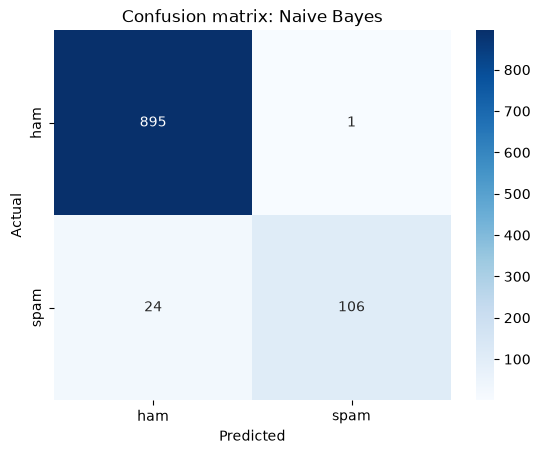

In [8]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["ham", "spam"], yticklabels=["ham", "spam"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix: Naive Bayes")
plt.show()

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Linear SVM": LinearSVC(),
}

rows = []
for name, m in models.items():
    m.fit(X_train_tfidf, y_train)
    pred = m.predict(X_test_tfidf)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
    })

results = pd.DataFrame(rows).round(4)
results

,Model,Accuracy,Precision,Recall,F1
0,Naive Bayes,0.9756,0.9907,0.8154,0.8945
1,Logistic Regression,0.9669,0.9898,0.7462,0.8509
2,Linear SVM,0.9834,0.9829,0.8846,0.9312


In [10]:
best = models["Linear SVM"]
best_pred = best.predict(X_test_tfidf)

wrong = y_test.index[y_test.values != best_pred]
df.loc[wrong, ["label", "message"]]

,label,message
658,spam,SMS. ac sun0819 posts HELLO:\You seem cool
2181,ham,Dont you have message offer
4949,spam,dating:i have had two of these. Only started a...
410,spam,Send a logo 2 ur lover - 2 names joined by a h...
1447,spam,Thanks for the Vote. Now sing along with the s...
1374,spam,For sale - arsenal dartboard. Good condition b...
2674,spam,Send a logo 2 ur lover - 2 names joined by a h...
4733,spam,PRIVATE! Your 2003 Account Statement for 078
4573,spam,"Hi this is Amy, we will be sending you a free ..."
1411,spam,Hi its LUCY Hubby at meetins all day Fri & I w...
